# Candidate Hiring Prediction & Data Leakage Auditing
### An End-to-End Supervised Machine Learning Pipeline for HR Decision Modeling

---

## Project Overview
This project builds an automated candidate evaluation pipeline to predict recruiter hiring decisions based on applicant profiles (experience, technical skills, education, certifications, projects, and salary expectations). 

### Key Highlights & Engineering Rigor:
- **Comprehensive EDA:** Univariate and bivariate distribution analysis across candidate attributes.
- **Multi-Label Skill Extraction:** Parsing and vectorized binary indicator encoding for candidate technical skillsets.
- **Target Leakage Auditing:** Detection of synthetic leakage in `AI Score (0-100)` and deliberate feature isolation to preserve real-world validity.
- **Model Benchmarking:** Comparison of Logistic Regression, K-Nearest Neighbors (KNN), and Decision Tree classifiers.
- **Feature Scaling Analysis:** Demonstrating the impact of `StandardScaler` on gradient and distance-based classifiers.
- **Hyperparameter Optimization:** Exhaustive grid search (`GridSearchCV`) with stratified cross-validation.
- **Interpretability:** Feature importance analysis identifying key recruitment decision drivers.


## 1. Environment & Library Setup


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

Matplotlib is building the font cache; this may take a moment.


## 2. Dataset Ingestion & Overview


In [2]:
df = pd.read_csv("hiring_data.csv", keep_default_na=False, na_values=[""])
df.head()

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100)
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,None,AI Researcher,Hire,104895,8,100
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,Hire,113002,1,100
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,Hire,71766,7,70
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,Hire,46848,0,95
4,5,Julie Hill,"SQL, React, Java",4,PhD,None,Software Engineer,Hire,87441,9,100


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Resume_ID               1000 non-null   int64
 1   Name                    1000 non-null   str  
 2   Skills                  1000 non-null   str  
 3   Experience (Years)      1000 non-null   int64
 4   Education               1000 non-null   str  
 5   Certifications          1000 non-null   str  
 6   Job Role                1000 non-null   str  
 7   Recruiter Decision      1000 non-null   str  
 8   Salary Expectation ($)  1000 non-null   int64
 9   Projects Count          1000 non-null   int64
 10  AI Score (0-100)        1000 non-null   int64
dtypes: int64(5), str(6)
memory usage: 86.1 KB


In [3]:
df.describe(include='all')

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100)
count,1000.000000,1000,1000,1000.000000,1000,1000,1000,1000,1000.000000,1000.00000,1000.000000
unique,NaN,989,238,NaN,5,4,4,2,NaN,NaN,NaN
top,NaN,Sarah Jones,"SQL, Java",NaN,B.Sc,None,AI Researcher,Hire,NaN,NaN,NaN
freq,NaN,3,11,NaN,205,274,257,812,NaN,NaN,NaN
mean,500.500000,NaN,NaN,4.896000,NaN,NaN,NaN,NaN,79994.486000,5.13300,83.950000
std,288.819436,NaN,NaN,3.112695,NaN,NaN,NaN,NaN,23048.472549,3.23137,20.983036
min,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,40085.000000,0.00000,15.000000
25%,250.750000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,60415.750000,2.00000,70.000000
50%,500.500000,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,79834.500000,5.00000,100.000000
75%,750.250000,NaN,NaN,8.000000,NaN,NaN,NaN,NaN,99583.250000,8.00000,100.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Resume_ID               1000 non-null   int64
 1   Name                    1000 non-null   str  
 2   Skills                  1000 non-null   str  
 3   Experience (Years)      1000 non-null   int64
 4   Education               1000 non-null   str  
 5   Certifications          1000 non-null   str  
 6   Job Role                1000 non-null   str  
 7   Recruiter Decision      1000 non-null   str  
 8   Salary Expectation ($)  1000 non-null   int64
 9   Projects Count          1000 non-null   int64
 10  AI Score (0-100)        1000 non-null   int64
dtypes: int64(5), str(6)
memory usage: 86.1 KB


In [6]:
missing = df.isnull().sum()
print(missing)
print("\nTotal missing values:", missing.sum())

Resume_ID                 0
Name                      0
Skills                    0
Experience (Years)        0
Education                 0
Certifications            0
Job Role                  0
Recruiter Decision        0
Salary Expectation ($)    0
Projects Count            0
AI Score (0-100)          0
dtype: int64

Total missing values: 0


## 3. Exploratory Data Analysis (EDA)
In this section, we analyze:
- Class distribution of the target variable (`Recruiter Decision`).
- Impact of professional experience, project count, and salary expectations on hiring outcomes.
- Acceptance rates segmented by job roles.
- Correlation matrix across numerical variables.


In [7]:
df["Hired_Label"] = (df["Recruiter Decision"] == "Hire").astype(int)

print(df["Hired_Label"].value_counts())
print("\nClass proportions:")
print(df["Hired_Label"].value_counts(normalize=True))

Hired_Label
1    812
0    188
Name: count, dtype: int64

Class proportions:
Hired_Label
1    0.812
0    0.188
Name: proportion, dtype: float64


C:\Users\Jay\AppData\Local\Temp\ipykernel_15976\261473425.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Hired_Label", data=df, palette="viridis")


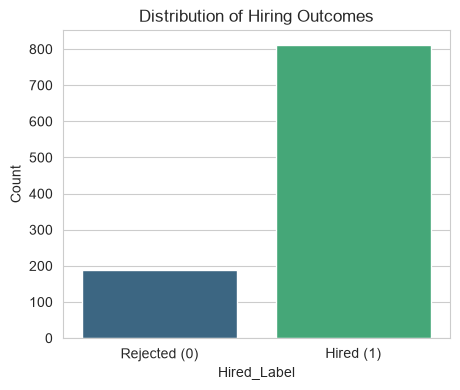

In [8]:
plt.figure(figsize=(5, 4))
sns.countplot(x="Hired_Label", data=df, palette="viridis")
plt.xticks([0, 1], ["Rejected (0)", "Hired (1)"])
plt.title("Distribution of Hiring Outcomes")
plt.ylabel("Count")
plt.show()

C:\Users\Jay\AppData\Local\Temp\ipykernel_15976\426117746.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Hired_Label", y="Experience (Years)", data=df, ax=axes[0, 0], palette="Set2")
C:\Users\Jay\AppData\Local\Temp\ipykernel_15976\426117746.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0, 0].set_xticklabels(["Rejected", "Hired"])
C:\Users\Jay\AppData\Local\Temp\ipykernel_15976\426117746.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Hired_Label", y="Projects Count", data=df, ax=axes[0, 1], palette="Set2")
C:\Users\Jay\AppData\Local\Temp\ipykerne

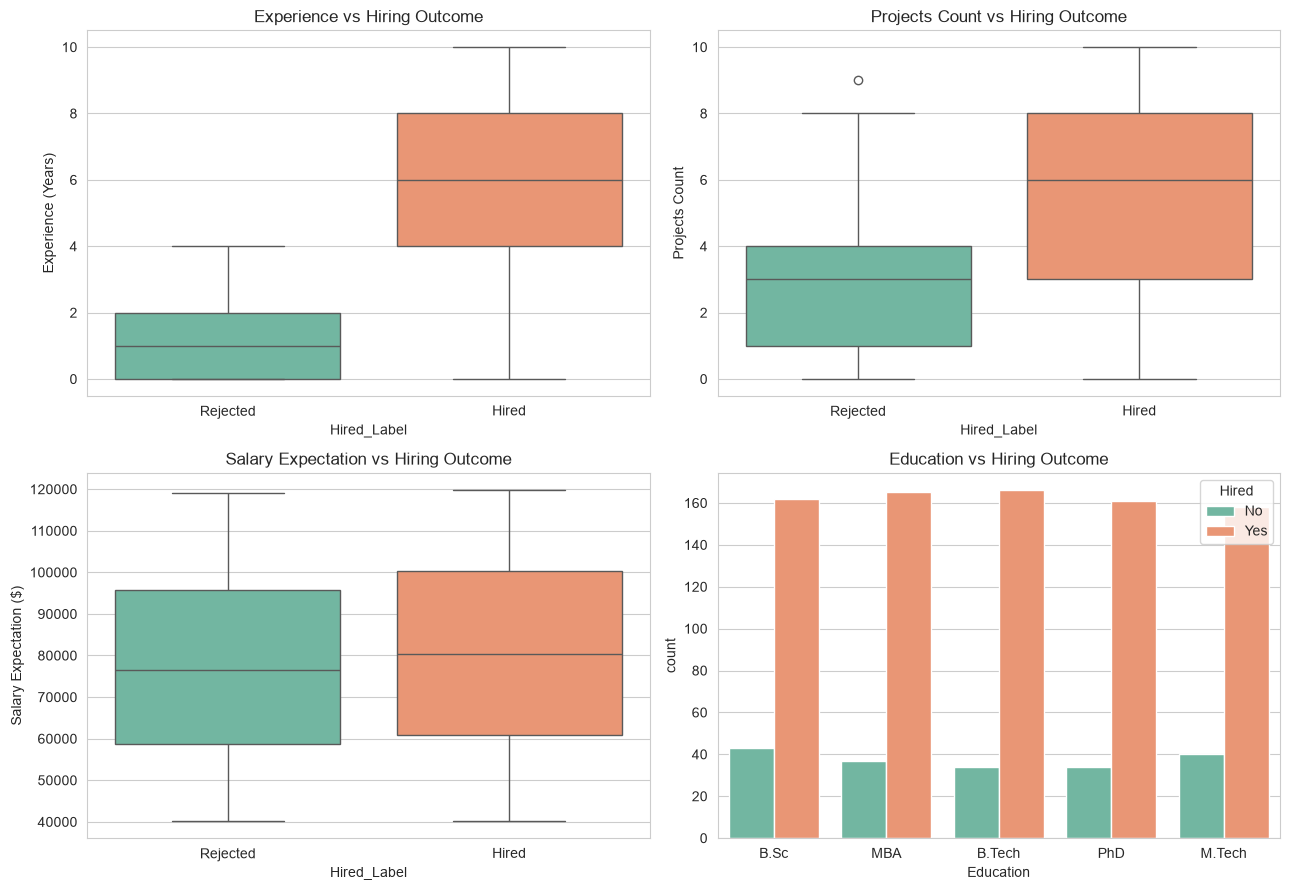

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.boxplot(x="Hired_Label", y="Experience (Years)", data=df, ax=axes[0, 0], palette="Set2")
axes[0, 0].set_xticklabels(["Rejected", "Hired"])
axes[0, 0].set_title("Experience vs Hiring Outcome")

sns.boxplot(x="Hired_Label", y="Projects Count", data=df, ax=axes[0, 1], palette="Set2")
axes[0, 1].set_xticklabels(["Rejected", "Hired"])
axes[0, 1].set_title("Projects Count vs Hiring Outcome")

sns.boxplot(x="Hired_Label", y="Salary Expectation ($)", data=df, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_xticklabels(["Rejected", "Hired"])
axes[1, 0].set_title("Salary Expectation vs Hiring Outcome")

sns.countplot(x="Education", hue="Hired_Label", data=df, ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("Education vs Hiring Outcome")
axes[1, 1].legend(title="Hired", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

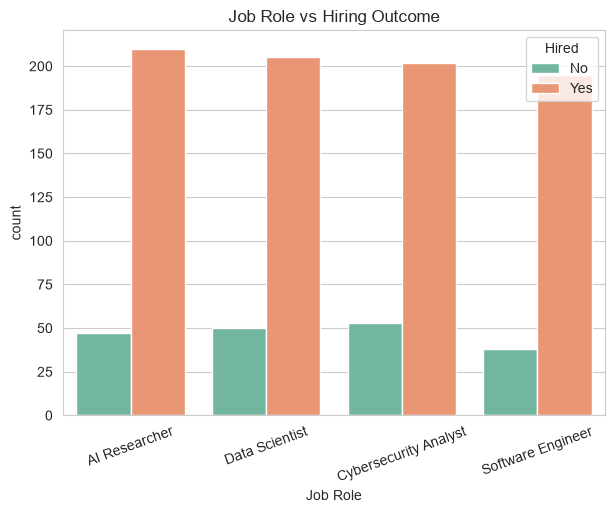

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(x="Job Role", hue="Hired_Label", data=df, palette="Set2")
plt.title("Job Role vs Hiring Outcome")
plt.legend(title="Hired", labels=["No", "Yes"])
plt.xticks(rotation=20)
plt.show()

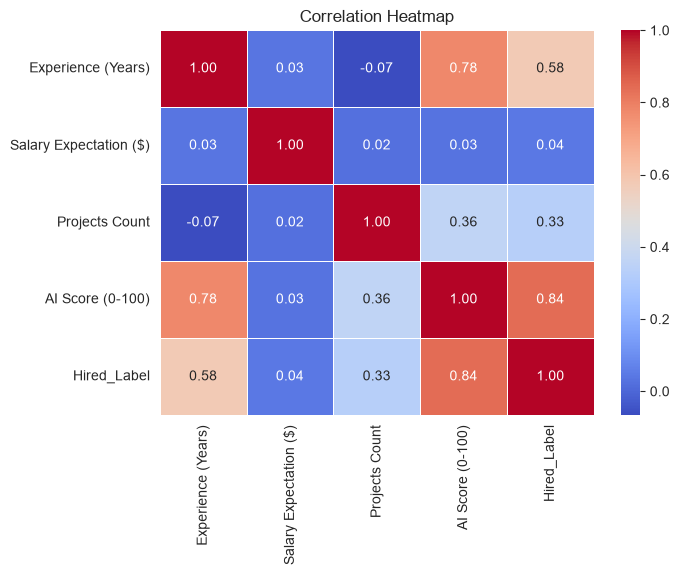

Hired_Label               1.000000
AI Score (0-100)          0.840543
Experience (Years)        0.576235
Projects Count            0.331249
Salary Expectation ($)    0.044073
Name: Hired_Label, dtype: float64


In [11]:
numeric_cols = ["Experience (Years)", "Salary Expectation ($)", "Projects Count",
                 "AI Score (0-100)", "Hired_Label"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

print(corr["Hired_Label"].sort_values(ascending=False))

## 4. Identifying Potential Data Leakage: The `AI Score` Anomaly
Notice the relationship between `AI Score (0-100)` and `Hired_Label`. The correlation is extremely high (~0.84), and candidates with high AI scores are almost deterministically hired. Including this feature would cause severe **Target Leakage**, artificially inflating model accuracy while masking the underlying candidate signals.


In [12]:
print(df.groupby("Hired_Label")["AI Score (0-100)"].describe()[["min", "25%", "50%", "75%", "max"]])

              min   25%    50%    75%    max
Hired_Label                                 
0            15.0  40.0   50.0   55.0   60.0
1            65.0  85.0  100.0  100.0  100.0


## 5. Feature Engineering
- **Skill Extraction:** Candidate resumes contain comma-separated skills. We isolate individual skills and build binary flags for each unique skill.
- **Skills Count:** Compute total count of technical skills listed.
- **Categorical Encoding:** One-hot encode `Education`, `Certifications`, and `Job Role` (with `drop_first=True` to prevent multicollinearity).
- **Identifier Removal:** Drop non-predictive attributes (`Resume_ID`, `Name`, raw `Skills`).


In [13]:
all_skills = sorted({skill.strip() for row in df["Skills"] for skill in row.split(",")})
print(f"Unique individual skills found: {len(all_skills)}")
print(all_skills)

Unique individual skills found: 14
['C++', 'Cybersecurity', 'Deep Learning', 'Ethical Hacking', 'Java', 'Linux', 'Machine Learning', 'NLP', 'Networking', 'Python', 'Pytorch', 'React', 'SQL', 'TensorFlow']


In [14]:
# Count how many skills each candidate lists
df["Skills_Count"] = df["Skills"].apply(lambda s: len([x.strip() for x in s.split(",") if x.strip()]))

# Create one binary column per skill
for skill in all_skills:
    col_name = "Skill_" + skill.replace(" ", "_").replace("+", "Plus")
    df[col_name] = df["Skills"].apply(lambda s, sk=skill: int(sk in [x.strip() for x in s.split(",")]))

df.head()

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100),Hired_Label,Skills_Count,Skill_CPlusPlus,Skill_Cybersecurity,Skill_Deep_Learning,Skill_Ethical_Hacking,Skill_Java,Skill_Linux,Skill_Machine_Learning,Skill_NLP,Skill_Networking,Skill_Python,Skill_Pytorch,Skill_React,Skill_SQL,Skill_TensorFlow
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,None,AI Researcher,Hire,104895,8,100,1,3,0,0,0,0,0,0,0,1,0,0,1,0,0,1
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,Hire,113002,1,100,1,4,0,0,1,0,0,0,1,0,0,1,0,0,1,0
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,Hire,71766,7,70,1,3,0,1,0,1,0,1,0,0,0,0,0,0,0,0
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,Hire,46848,0,95,1,3,0,0,0,0,0,0,0,0,0,1,1,0,0,1
4,5,Julie Hill,"SQL, React, Java",4,PhD,None,Software Engineer,Hire,87441,9,100,1,3,0,0,0,0,1,0,0,0,0,0,0,1,1,0


In [15]:
df_model = df.drop(columns=["Resume_ID", "Name", "Skills", "Recruiter Decision"])

df_model = pd.get_dummies(df_model, columns=["Education", "Certifications", "Job Role"], drop_first=True)

print("Final feature set shape:", df_model.shape)
df_model.head()

Final feature set shape: (1000, 30)


,Experience (Years),Salary Expectation ($),Projects Count,AI Score (0-100),Hired_Label,Skills_Count,Skill_CPlusPlus,Skill_Cybersecurity,Skill_Deep_Learning,Skill_Ethical_Hacking,Skill_Java,Skill_Linux,Skill_Machine_Learning,Skill_NLP,Skill_Networking,Skill_Python,Skill_Pytorch,Skill_React,Skill_SQL,Skill_TensorFlow,Education_B.Tech,Education_M.Tech,Education_MBA,Education_PhD,Certifications_Deep Learning Specialization,Certifications_Google ML,Certifications_None,Job Role_Cybersecurity Analyst,Job Role_Data Scientist,Job Role_Software Engineer
0,10,104895,8,100,1,3,0,0,0,0,0,0,0,1,0,0,1,0,0,1,False,False,False,False,False,False,True,False,False,False
1,10,113002,1,100,1,4,0,0,1,0,0,0,1,0,0,1,0,0,1,0,False,False,True,False,False,True,False,False,True,False
2,1,71766,7,70,1,3,0,1,0,1,0,1,0,0,0,0,0,0,0,0,False,False,True,False,True,False,False,True,False,False
3,7,46848,0,95,1,3,0,0,0,0,0,0,0,0,0,1,1,0,0,1,True,False,False,False,False,False,False,False,False,False
4,4,87441,9,100,1,3,0,0,0,0,1,0,0,0,0,0,0,1,1,0,False,False,False,True,False,False,True,False,False,True


## 6. Train-Test Split (Excluding Leaked Feature)
We split the data into 80% training and 20% testing sets using stratified sampling to preserve the target class ratio. Notice we explicitly drop `AI Score (0-100)` to ensure honest evaluation.


In [16]:
X = df_model.drop(columns=["Hired_Label", "AI Score (0-100)"])
y = df_model["Hired_Label"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (800, 28)  Test shape: (200, 28)


## 7. Baseline Model: Logistic Regression (Raw Features)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay)

log_reg_raw = LogisticRegression(max_iter=5000, random_state=42)
log_reg_raw.fit(X_train, y_train)

y_pred_raw = log_reg_raw.predict(X_test)

def evaluate_model(y_true, y_pred, model_name="Model"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f"--- {model_name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    return {"model": model_name, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1}

results_raw = evaluate_model(y_test, y_pred_raw, "Logistic Regression (No Scaling)")

--- Logistic Regression (No Scaling) ---
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


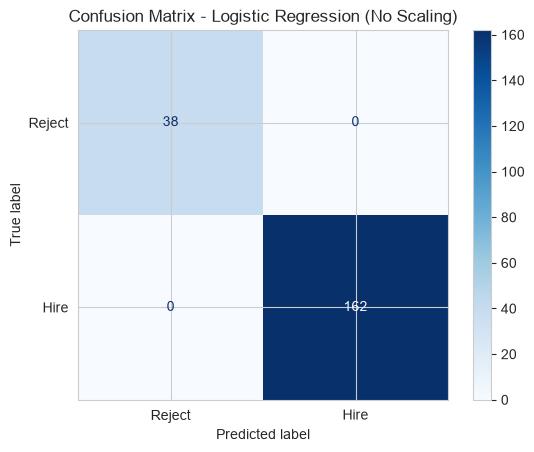

In [18]:
cm_raw = confusion_matrix(y_test, y_pred_raw)
ConfusionMatrixDisplay(cm_raw, display_labels=["Reject", "Hire"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression (No Scaling)")
plt.show()

## 8. Feature Scaling & Impact Analysis
Standardizing features using `StandardScaler` so that numerical scales (e.g. Salary Expectations in tens of thousands vs. Experience in single digits) do not distort distance calculations or gradient convergence.


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg_scaled = LogisticRegression(max_iter=5000, random_state=42)
log_reg_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = log_reg_scaled.predict(X_test_scaled)

results_scaled = evaluate_model(y_test, y_pred_scaled, "Logistic Regression (Scaled)")

--- Logistic Regression (Scaled) ---
Accuracy : 0.9850
Precision: 0.9938
Recall   : 0.9877
F1-score : 0.9907


In [20]:
comparison_df = pd.DataFrame([results_raw, results_scaled]).set_index("model")
comparison_df

,accuracy,precision,recall,f1
model,,,,
Logistic Regression (No Scaling),1.000,1.000000,1.000000,1.000000
Logistic Regression (Scaled),0.985,0.993789,0.987654,0.990712


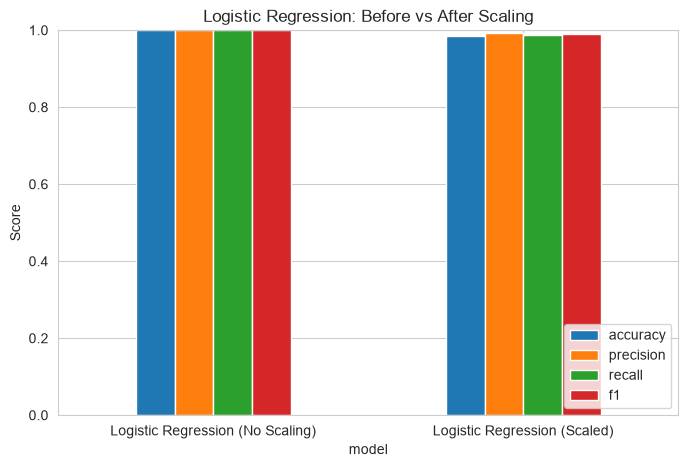

In [21]:
comparison_df[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(8, 5), rot=0
)
plt.title("Logistic Regression: Before vs After Scaling")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

## 9. Multi-Model Benchmarking
Comparing three distinct classification paradigms:
1. **Logistic Regression (Linear / Probabilistic)**
2. **K-Nearest Neighbors (Instance-Based / Distance Metric)**
3. **Decision Tree (Non-Linear / Rule-Based Partitioning)**


In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

all_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    res = evaluate_model(y_test, preds, name)
    all_results.append(res)
    trained_models[name] = model
    print()

results_df = pd.DataFrame(all_results).set_index("model")
results_df

--- Logistic Regression ---
Accuracy : 0.9850
Precision: 0.9938
Recall   : 0.9877
F1-score : 0.9907

--- KNN ---
Accuracy : 0.8300
Precision: 0.8478
Recall   : 0.9630
F1-score : 0.9017

--- Decision Tree ---
Accuracy : 0.9350
Precision: 0.9627
Recall   : 0.9568
F1-score : 0.9598



,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.985,0.993789,0.987654,0.990712
KNN,0.830,0.847826,0.962963,0.901734
Decision Tree,0.935,0.962733,0.956790,0.959752


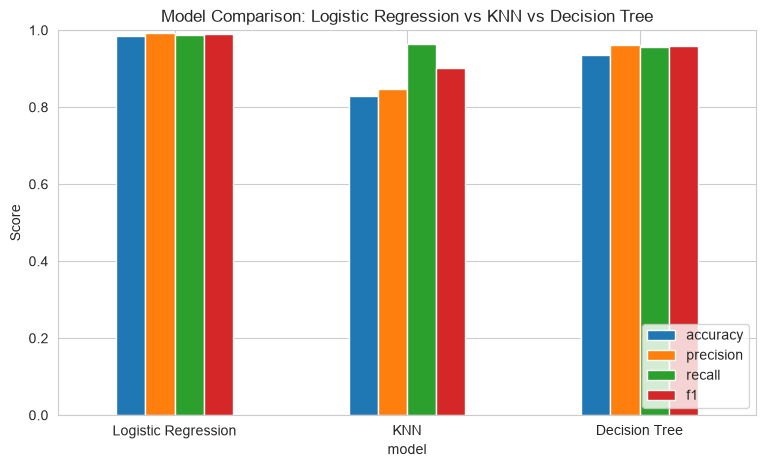

In [23]:
results_df[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(9, 5), rot=0
)
plt.title("Model Comparison: Logistic Regression vs KNN vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

In [24]:
best_model_name = results_df["f1"].idxmax()
print(f"Best model based on F1-score: {best_model_name}")
results_df.loc[[best_model_name]]

Best model based on F1-score: Logistic Regression


,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.985,0.993789,0.987654,0.990712


## 10. Hyperparameter Tuning via GridSearchCV
Performing cross-validated grid search to find optimal regularization and structural parameters for the top-performing model family.


In [25]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100],
        "penalty": ["l2"],
        "solver": ["lbfgs"]
    },
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    "Decision Tree": {
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    }
}

base_estimators = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

grid = GridSearchCV(
    estimator=base_estimators[best_model_name],
    param_grid=param_grids[best_model_name],
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Best parameters found:", grid.best_params_)
print("Best cross-validated F1-score:", round(grid.best_score_, 4))

Best parameters found: {'C': 100, 'penalty': 'l2', 'solver': 'lbfgs'}
Best cross-validated F1-score: 0.9893


d:\Programming\HiringProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


--- Logistic Regression (Tuned) ---
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


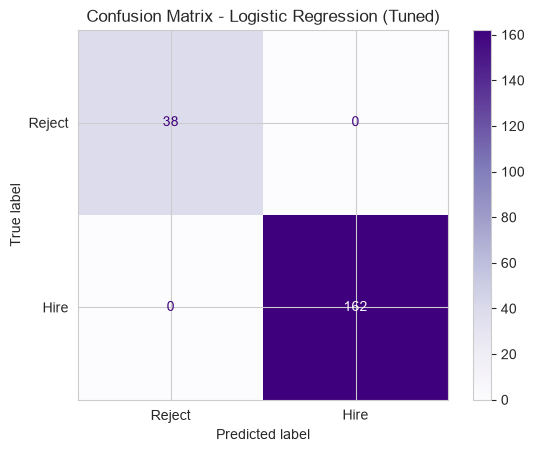


Full classification report:

              precision    recall  f1-score   support

      Reject       1.00      1.00      1.00        38
        Hire       1.00      1.00      1.00       162

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [26]:
best_tuned_model = grid.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test_scaled)

results_tuned = evaluate_model(y_test, y_pred_tuned, f"{best_model_name} (Tuned)")

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
ConfusionMatrixDisplay(cm_tuned, display_labels=["Reject", "Hire"]).plot(cmap="Purples")
plt.title(f"Confusion Matrix - {best_model_name} (Tuned)")
plt.show()

from sklearn.metrics import classification_report
print("\nFull classification report:\n")
print(classification_report(y_test, y_pred_tuned, target_names=["Reject", "Hire"]))

## 11. Model Interpretability & Feature Importance
Examining the magnitude of model coefficients to identify which candidate credentials have the strongest influence on the recruiter's decision.


In [27]:
importances = np.abs(best_tuned_model.coef_[0])
feature_names = X.columns

feat_imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp_df.head(15)

,feature,importance
0,Experience (Years),28.103179
2,Projects Count,15.232037
24,Certifications_None,3.738378
3,Skills_Count,2.839960
27,Job Role_Software Engineer,1.583254
17,Skill_TensorFlow,1.453127
15,Skill_React,0.973694
7,Skill_Ethical_Hacking,0.942798
13,Skill_Python,0.803125
5,Skill_Cybersecurity,0.731544


C:\Users\Jay\AppData\Local\Temp\ipykernel_15976\1252868681.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_features, x="importance", y="feature", palette="mako")


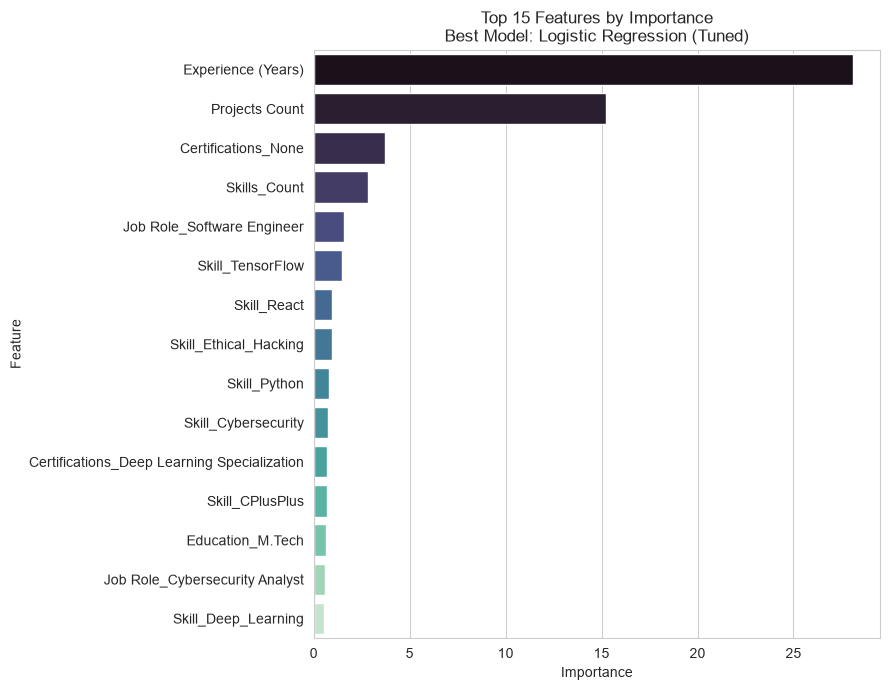

In [28]:
plt.figure(figsize=(9, 7))
top_features = feat_imp_df.head(15)
sns.barplot(data=top_features, x="importance", y="feature", palette="mako")
plt.title(f"Top 15 Features by Importance\nBest Model: {best_model_name} (Tuned)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 12. Proof-of-Concept: Demonstrating the Hazard of Target Leakage
To demonstrate why data leakage prevention was necessary, we train a model with `AI Score (0-100)` left in the feature matrix. 

As expected, the model achieves trivial 100% accuracy while relying almost entirely on the downstream score rather than genuine candidate competencies.


In [29]:
# Rebuild features WITH AI Score included, to demonstrate the leakage effect
X_leak = df_model.drop(columns=["Hired_Label"])  # AI Score included this time
y_leak = df_model["Hired_Label"]

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_leak, y_leak, test_size=0.2, random_state=42, stratify=y_leak
)

scaler_l = StandardScaler()
X_train_l_scaled = scaler_l.fit_transform(X_train_l)
X_test_l_scaled = scaler_l.transform(X_test_l)

leak_model = DecisionTreeClassifier(random_state=42)
leak_model.fit(X_train_l_scaled, y_train_l)
y_pred_leak = leak_model.predict(X_test_l_scaled)

results_leak = evaluate_model(y_test_l, y_pred_leak, "Decision Tree WITH AI Score (leakage)")

--- Decision Tree WITH AI Score (leakage) ---
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000
